# Mediciones con ruido y mínimos cuadrados

Continuaremos utilizando el vector $x_{\text{fantoma}}$ del Ejercicio 1 y la matriz $A_7$. Las mediciones ideales son $b_7 = A_7\,x_{\text{fantoma}}$. Para simular una adquisición real, agregaremos ruido y obtendremos mediciones perturbadas $b_\sigma = b_7 + \eta_\sigma$. Debido al ruido, en general no existirá una imagen que reproduzca exactamente todas las mediciones. Utilizaremos mínimos cuadrados para encontrar la imagen cuyas mediciones simuladas sean lo más cercanas posible a $b_\sigma$.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt


# Fantoma del ejercicio 1 (matriz y vector)
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_v_fantoma = X_fantoma.reshape(-1)


# Funciones de los ejercicios 2 y 3 (copiadas para que el notebook sea autocontenido)
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n))
    i, j = np.ogrid[:n, :n]
    condicion = (i * direccion[0] + j * direccion[1] == s)   # píxeles cuyo centro cumple α·i + β·j = s
    M[condicion] = 1
    return M


def matriz_proyeccion(n, direcciones):
    i, j = np.indices((n, n))
    filas = []    # filas de A, una por rayo
    rayos = []    # par ((α, β), s) de cada fila
    for (alfa, beta) in direcciones:
        S = alfa * i + beta * j               # a qué rayo pertenece cada píxel
        for s in np.unique(S):                # cada valor distinto de s es un rayo
            M = mascara_rayo(n, (alfa, beta), s)
            filas.append(M.reshape(-1))       # máscara vectorizada -> fila de A
            rayos.append(((alfa, beta), int(s)))
    A = np.array(filas, dtype=float)
    return A, rayos


# Matriz A7 del ejercicio 4
D7 = [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1), (1, 2), (3, 1)]
A7, rayos7 = matriz_proyeccion(8, D7)

# Mediciones ideales (sin ruido)
b7 = A7 @ x_v_fantoma

#### a) Fijar una semilla aleatoria y generar un único vector $z$, del mismo tamaño que $b_7$, con componentes gaussianas estándar. Calcular `escala = np.sqrt(np.mean(b7**2))`; este valor representa el tamaño típico de las mediciones. Para cada $\sigma \in \{0,\ 0.01,\ 0.03,\ 0.06,\ 0.10\}$, definir $\eta_\sigma = \sigma \cdot \text{escala} \cdot z$ y construir $b_\sigma$. De este modo, $\sigma = 0.03$ representa un ruido cuya desviación estándar es aproximadamente el 3 % del tamaño típico de las mediciones.

In [3]:
# Semilla fija para cada vez que se corre el notebook se obtiene el mismo vector z
rng = np.random.default_rng(42)

# Vector con componentes gaussianas estándar, del mismo tamaño que b7
z = rng.standard_normal(b7.shape[0])

# Tamaño de las mediciones
escala = np.sqrt(np.mean(b7**2))
print(f"Cantidad de mediciones: {b7.shape[0]}")
print(f"escala = {escala:.4f}\n")

sigmas = [0, 0.01, 0.03, 0.06, 0.10]
mediciones_ruido = {}   # b_sigma para cada nivel de ruido
ruidos = {}             # eta_sigma para cada nivel de ruido

for sigma in sigmas:
    eta = sigma * escala * z          # ruido: mismo z, solo cambia la intensidad
    ruidos[sigma] = eta
    mediciones_ruido[sigma] = b7 + eta
    print(f"sigma = {sigma:<5} ||eta|| = {np.linalg.norm(eta):.4f}")

Cantidad de mediciones: 119
escala = 1.0963

sigma = 0     ||eta|| = 0.0000
sigma = 0.01  ||eta|| = 0.0941
sigma = 0.03  ||eta|| = 0.2823
sigma = 0.06  ||eta|| = 0.5647
sigma = 0.1   ||eta|| = 0.9411


Tal como pide la consigna se fijó una semilla para que el vector $z$ sea siempre el mismo cada vez que se corre el notebook, y se generó un único $z$ que se usara para todos los niveles de ruido. Por ende, entre un $\sigma$ y otro lo único que cambia es la intensidad del ruido, no su forma ya que $\eta_\sigma$ es siempre el mismo vector $z$ multiplicado por un número distinto.

`escala` es la raíz del promedio de las mediciones al cuadrado, es decir, el tamaño típico de una medición (≈ 1.10). Al multiplicar $z$ por $\sigma \cdot \text{escala}$, el ruido queda expresado en relación al tamaño de las mediciones.

#### b) Para cada nivel de ruido, utilizar `np.linalg.lstsq` para obtener la reconstrucción $\hat{x}_\sigma$ que minimiza $\|A_7 x - b_\sigma\|^2$. Registrar en una tabla la norma del ruido, la norma del residuo, el error relativo respecto de $x_{\text{fantoma}}$ y los valores mínimo y máximo de la reconstrucción. Visualizar las imágenes reconstruidas utilizando una misma escala de color.

In [4]:
norma_fantoma = np.linalg.norm(x_v_fantoma)
reconstrucciones = {}

print(f"{'sigma':<7}{'||eta||':>9}{'||r||':>9}{'Error relativo':>16}{'mín x̂':>9}{'máx x̂':>9}")
for sigma in sigmas:
    #Tomar las mediciones con ruido
    b_sigma = mediciones_ruido[sigma]

    # Reconstrucción por mínimos cuadrados
    # Se minimiza ||A7 x - b_sigma||^2
    x_hat, _, _, _ = np.linalg.lstsq(A7, b_sigma, rcond=None)
    reconstrucciones[sigma] = x_hat

    norma_ruido = np.linalg.norm(ruidos[sigma])
    norma_residuo = np.linalg.norm(b_sigma - A7 @ x_hat)                  # r = b_sigma - A7 x̂
    error_relativo = np.linalg.norm(x_hat - x_v_fantoma) / norma_fantoma

    print(f"{sigma:<7}{norma_ruido:>9.4f}{norma_residuo:>9.4f}{error_relativo:>16.4f}{x_hat.min():>9.3f}{x_hat.max():>9.3f}")

sigma    ||eta||    ||r||  Error relativo   mín x̂   máx x̂
0         0.0000   0.0000          0.0000   -0.000    0.800
0.01      0.0941   0.0585          0.0163   -0.012    0.811
0.03      0.2823   0.1755          0.0488   -0.037    0.834
0.06      0.5647   0.3511          0.0975   -0.074    0.867
0.1       0.9411   0.5851          0.1626   -0.123    0.912


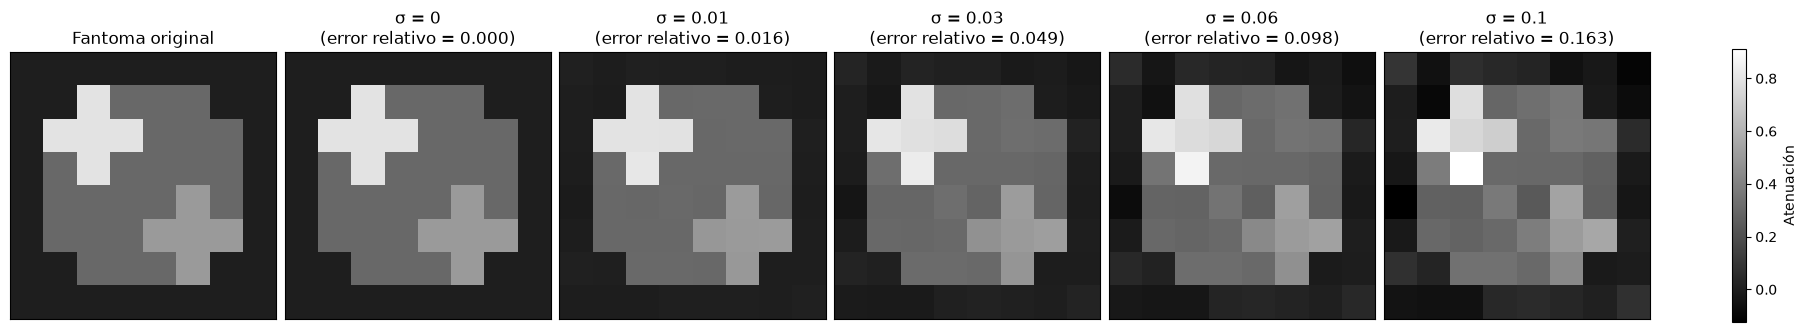

In [5]:
# Misma escala de color para todas las imágenes
imagenes = [X_fantoma] + [reconstrucciones[s].reshape(8, 8) for s in sigmas]
vmin = min(img.min() for img in imagenes)
vmax = max(img.max() for img in imagenes)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.6), layout='constrained')

im = axes[0].imshow(X_fantoma, cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title('Fantoma original')

for ax, sigma in zip(axes[1:], sigmas):
    error = np.linalg.norm(reconstrucciones[sigma] - x_v_fantoma) / norma_fantoma
    ax.imshow(reconstrucciones[sigma].reshape(8, 8), cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(f'σ = {sigma}\n(error relativo = {error:.3f})')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(im, ax=axes, shrink=0.8, label='Atenuación')
plt.savefig('figuras/ejercicio_06b.png', dpi=150, bbox_inches='tight')
plt.show()

Las imágenes se graficaron con la misma escala de color, por lo que un mismo tono representa el mismo valor en todas. Con $\sigma = 0$ la reconstrucción es igual al fantoma, como en el Ejercicio 5. A medida que aumenta $\sigma$, la forma general del fantoma se sigue reconociendo, pero aparecen variaciones entre píxeles que en el fantoma valían lo mismo, y los valores se salen del rango original $[0,\ 0.8]$.

#### c) Analizar los resultados: ¿cómo cambia el error de reconstrucción al aumentar $\sigma$? ¿Por qué el residuo deja de ser nulo cuando se agrega ruido? ¿Por qué pueden aparecer valores negativos, aunque los coeficientes de atenuación del fantoma sean no negativos?

El error relativo crece al aumentar el ruido, y lo hace de forma proporcional, si se divide el error por $\sigma$, da siempre ≈ 1.63 (por ejemplo, $0.0975 / 0.06 \approx 0.1626 / 0.10 \approx 1.63$). Es decir, duplicar el ruido duplica el error. Esto se puede ver con la fórmula de mínimos cuadrados. Como $A_7$ tiene columnas linealmente independientes (rango 64), la solución de mínimos cuadrados es única y se obtiene multiplicando $b_\sigma$ siempre por la misma matriz, $(A_7^TA_7)^{-1}A_7^T$. Por linealidad, la reconstrucción se puede separar en lo que viene de las mediciones limpias, que es el fantoma, y lo que viene del ruido, que es el error. Como el ruido es siempre el mismo vector $z$ multiplicado por $\sigma$, el error también es siempre el mismo patrón multiplicado por $\sigma$.

Como se vio en el ejercicio 5, sin ruido, $b_7 = A_7 x_{\text{fantoma}}$ es una combinación lineal de las columnas de $A_7$, es decir, $b_7 \in \text{Col}(A_7)$, y el sistema tiene solución unica y exacta. Pero $\text{Col}(A_7)$ tiene dimensión 64 (el rango) dentro de $\mathbb{R}^{119}$, así que no contiene a todos los vectores posibles de mediciones. Al sumarle el ruido, $b_\sigma$ en general queda fuera de $\text{Col}(A_7)$. El sistema $A_7 x = b_\sigma$ se vuelve inconsistente y no existe ninguna imagen que reproduzca exactamente todas las mediciones, como anticipa la consigna. Por eso `lstsq` encuentra la imagen cuyas mediciones $A_7\hat{x}_\sigma$ están lo más cerca posible de $b_\sigma$, pero la distancia entre ambas(el residuo) ya no es cero. En la tabla se ve que el residuo crece junto con el ruido.

Mínimos cuadrados busca el $x$ que minimiza $\|A_7 x - b_\sigma\|^2$ sin ninguna restricción sobre los valores de $x$, es decir matematicamente hablando puede tomar cualquier valor real, también negativo. Al tratar de ajustarse a mediciones con ruido, la reconstrucción modifica los valores de los píxeles y algunos que en el fantoma valían 0 quedan por debajo de cero. En la tabla se ve que, sin ruido el mínimo es 0 y que a medida que crece $\sigma$ el mínimo es cada vez más negativo (hasta ≈ −0.12), mientras que el máximo supera cada vez más el valor real de 0.8.

Llevándolo a la practica, este ejercicio muestra que aunque el escáner tenga suficientes direcciones para no tener puntos ciegos (como $A_7$), eso no alcanza para recuperar la imagen exacta, porque las mediciones reales siempre tienen ruido.por eso hay que tratar de alcanar la mejor aproximación posible, que es la que da mínimos cuadrados.
